In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files
df = files.upload()

Saving cardekho-selected-columns.csv to cardekho-selected-columns (1).csv


In [ ]:
df = pd.read_csv("/content/cardekho-selected-columns.csv")

In [ ]:
df.shape

(8128, 10)

In [ ]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0


In [ ]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.30,1248.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0


In [ ]:
df.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
dtypes: float64(2), int64(3), object(5)
memory usage: 635.1+ KB


In [ ]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),221
engine,221


In [ ]:
# Check inconsistent categories
df['fuel'].unique()

array(['Diesel', 'Petrol', 'LPG', 'CNG'], dtype=object)

In [ ]:
df['transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [ ]:
df['seller_type'].unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [ ]:
df['owner'].unique()

array(['First Owner', 'Second Owner', 'Third Owner',
       'Fourth & Above Owner', 'Test Drive Car'], dtype=object)

In [ ]:
# Categorical descriptive statistics
df.describe(include = "object")

,name,fuel,seller_type,transmission,owner
count,8128,8128,8128,8128,8128
unique,2058,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,129,4402,6766,7078,5289


In [ ]:
df.describe(include = "number")

,year,selling_price,km_driven,mileage(km/ltr/kg),engine
count,6926.000000,6.926000e+03,6926.000000,6926.000000,6926.000000
mean,2013.460872,4.704444e+05,72188.995668,19.479628,1362.007003
std,3.934351,2.943957e+05,43440.909202,3.901597,340.650096
min,2002.000000,2.999900e+04,1.000000,8.895000,745.500000
25%,2011.000000,2.500000e+05,40000.000000,16.950000,1197.000000
50%,2014.000000,4.000000e+05,70000.000000,19.418783,1248.000000
75%,2017.000000,6.335000e+05,100000.000000,22.320000,1498.000000
max,2020.000000,1.208750e+06,190000.000000,30.375000,1949.500000


In [ ]:
# Replacing the Null Values with mean
df['mileage(km/ltr/kg)'] = df['mileage(km/ltr/kg)'].fillna(df['mileage(km/ltr/kg)'].mean())
df['engine'] = df['engine'].fillna(df['engine'].mean())


In [ ]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),0
engine,0


In [ ]:
df.duplicated().sum()

np.int64(1202)

In [ ]:
# In case duplicates exist
df.drop_duplicates(inplace = True)

In [ ]:
df.duplicated().sum()

np.int64(0)

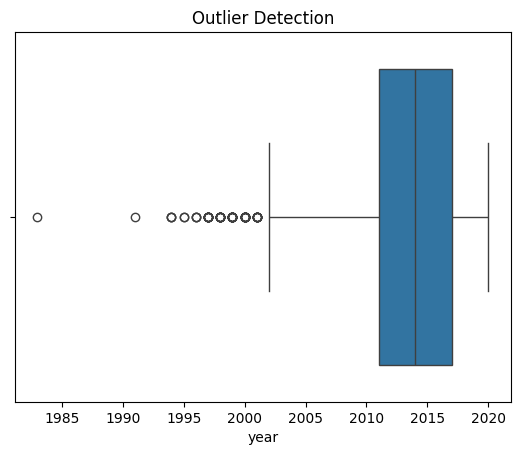

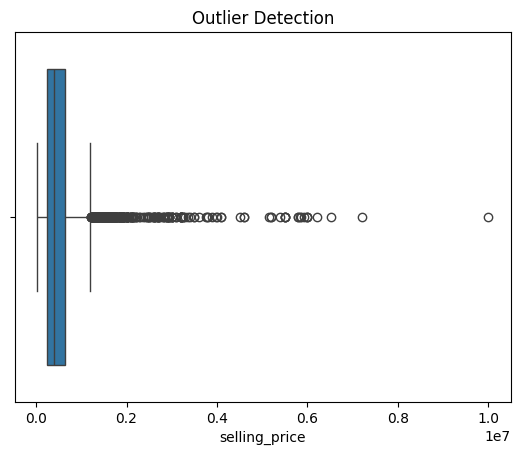

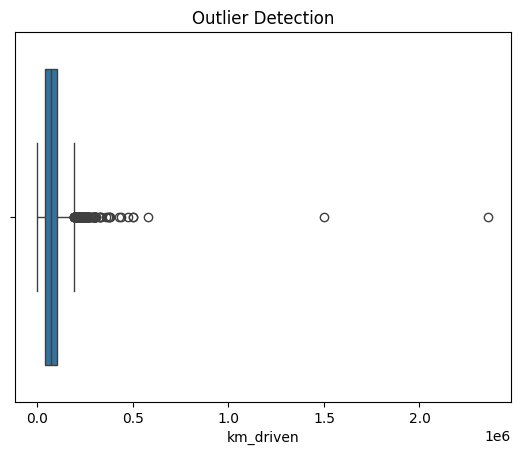

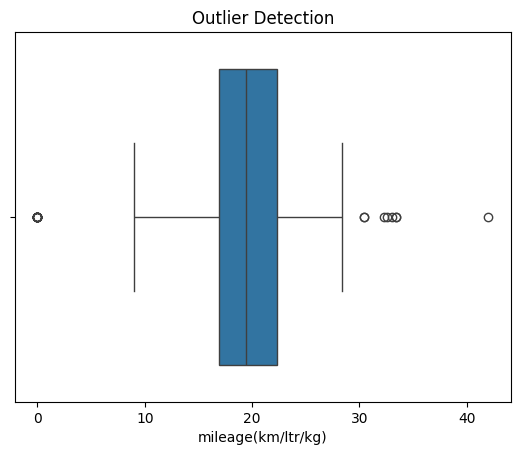

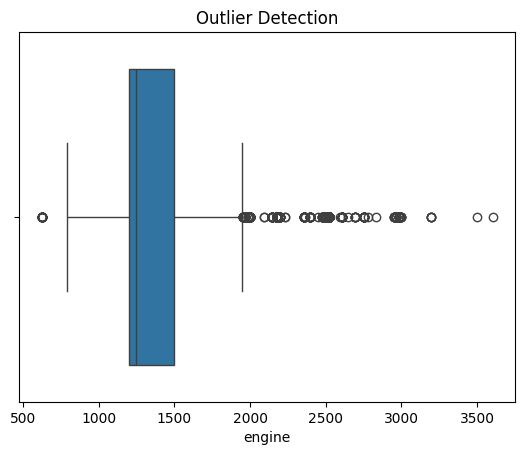

In [ ]:
# Outlier Treatment
for col in df.select_dtypes(include = "number"):
  sns.boxplot(x = df[col])
  plt.title("Outlier Detection")
  plt.show()


In [ ]:
#Outlier Treatment
for col in df.select_dtypes(include = "number"):
   Q1 = df[col].quantile(0.25)
   Q3 = df[col].quantile(0.75)
   IQR = Q3 - Q1
   lower = Q1 - 1.5 * IQR
   upper = Q3 + 1.5 * IQR
   df[col] = df[col].clip(lower,upper)

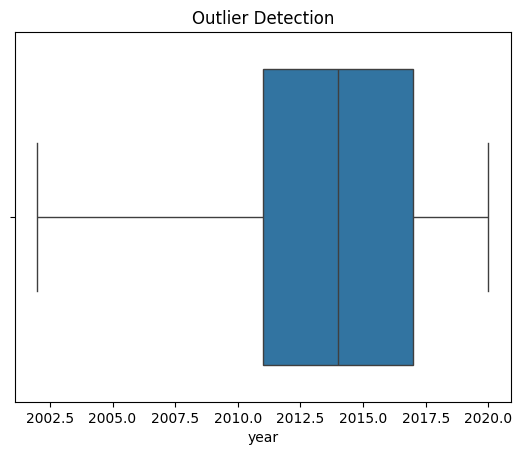

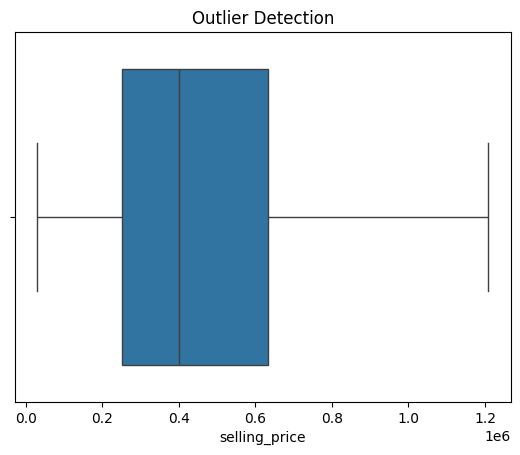

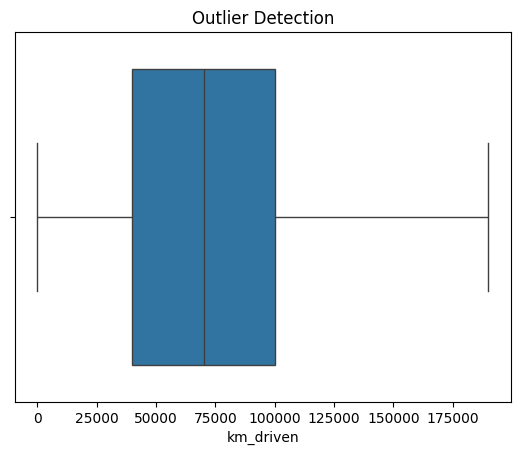

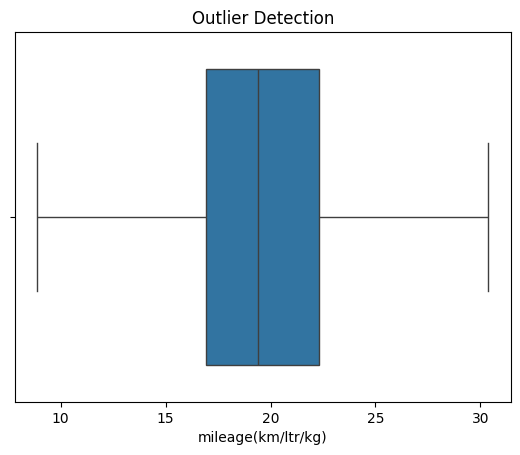

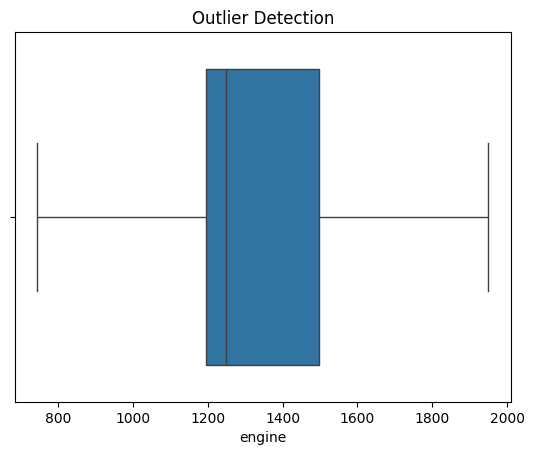

In [ ]:
for col in df.select_dtypes(include = "number"):
  sns.boxplot(x = df[col])
  plt.title("Outlier Detection")
  plt.show()

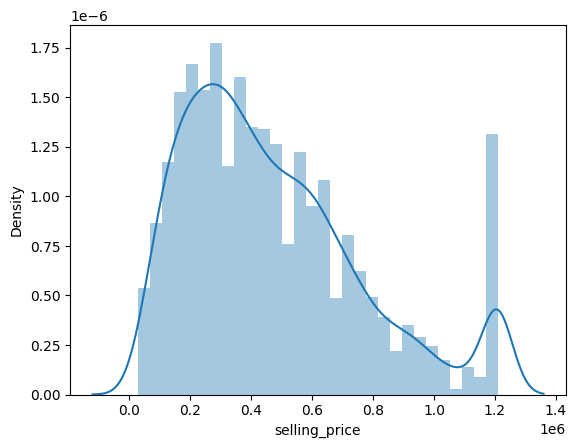

In [ ]:
# univariate Analysis
sns.distplot(df['selling_price'])
plt.show()

In [ ]:
df.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine
count,6926.000000,6.926000e+03,6926.000000,6926.000000,6926.000000
mean,2013.460872,4.704444e+05,72188.995668,19.479628,1362.007003
std,3.934351,2.943957e+05,43440.909202,3.901597,340.650096
min,2002.000000,2.999900e+04,1.000000,8.895000,745.500000
25%,2011.000000,2.500000e+05,40000.000000,16.950000,1197.000000
50%,2014.000000,4.000000e+05,70000.000000,19.418783,1248.000000
75%,2017.000000,6.335000e+05,100000.000000,22.320000,1498.000000
max,2020.000000,1.208750e+06,190000.000000,30.375000,1949.500000


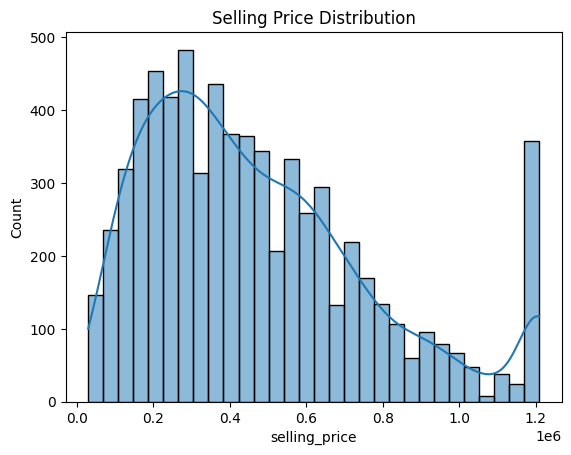

In [ ]:
# Univariate Analysis
sns.histplot(df['selling_price'], kde = True)
plt.title('Selling Price Distribution')
plt.show()

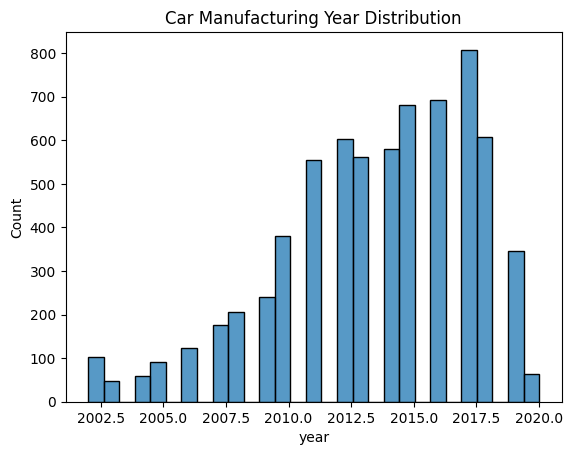

In [ ]:
sns.histplot(df['year'])
plt.title('Car Manufacturing Year Distribution')
plt.show()

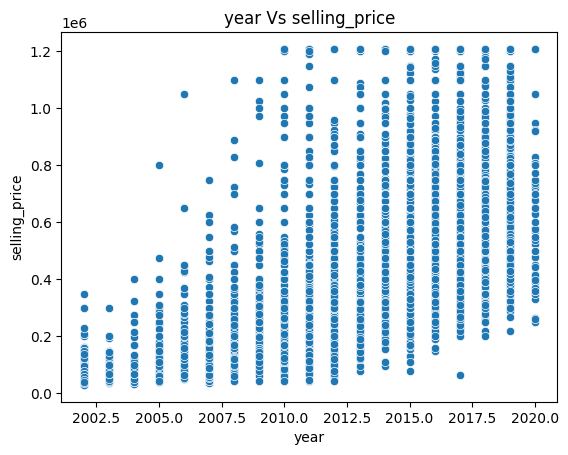

In [ ]:
# Bivariate Analysis
sns.scatterplot(x ='year', y ="selling_price", data = df)
plt.title('year Vs selling_price')
plt.show()

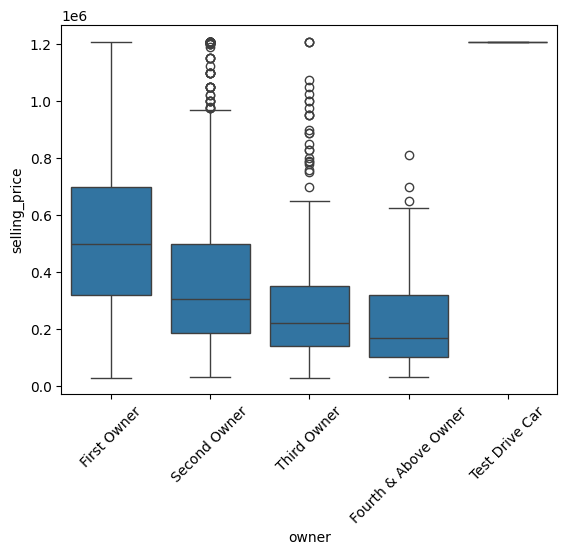

In [ ]:
sns.boxplot(x='owner', y='selling_price', data=df)
plt.xticks(rotation=45)
plt.show()

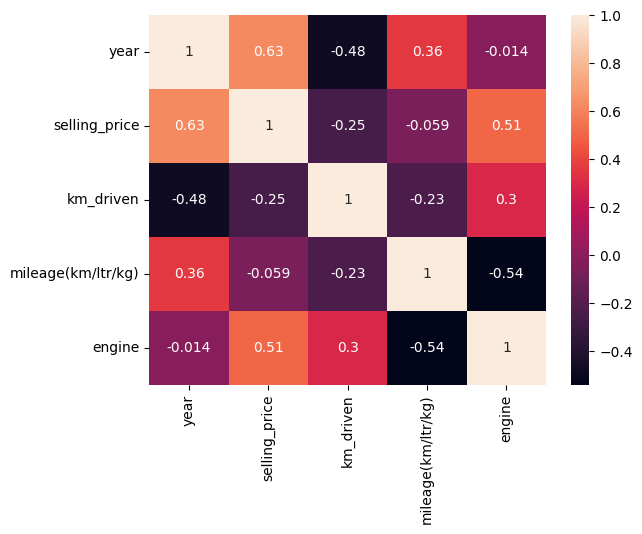

In [ ]:
# Multivariate Analysis
sns.heatmap(df.select_dtypes(include = "number").corr(),annot = True)
plt.show()

In [ ]:
# -------Question And Answers-------

In [37]:
# Q1. Which brands or fuel types are most common?
df['brand'] = df['name'].str.split().str[0]
df['brand'].value_counts()
# o/p : topmost brand is most common

,count
brand,
Maruti,2165
Hyundai,1267
Mahindra,723
Tata,647
Honda,362
Ford,361
Toyota,357
Chevrolet,216
Renault,206


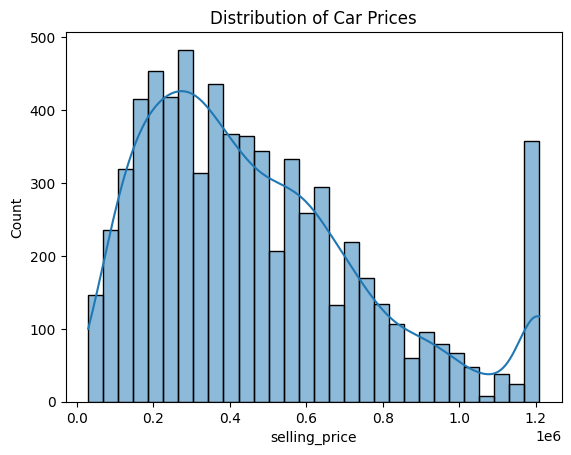

In [38]:
# How are car prices distributed?
sns.histplot(df['selling_price'], kde = True)
plt.title("Distribution of Car Prices")
plt.show()

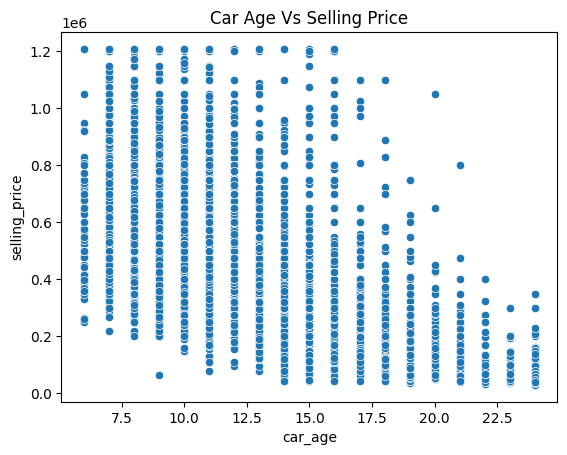

In [40]:
# Q3. How does vehicle age relate to price?
df['car_age'] = 2026 - df['year']
sns.scatterplot(x = 'car_age', y = 'selling_price', data = df)
plt.title('Car Age Vs Selling Price')
plt.show()

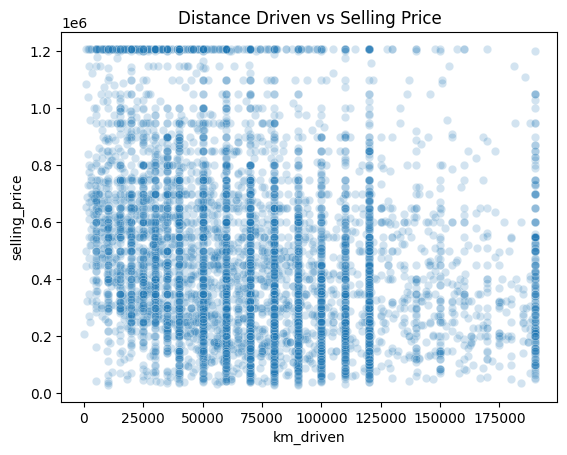

In [54]:
# Q4. Does mileage appear to influence price?
sns.scatterplot(x='km_driven', y='selling_price', data=df, alpha=0.2)
plt.title('Distance Driven vs Selling Price')
plt.show()

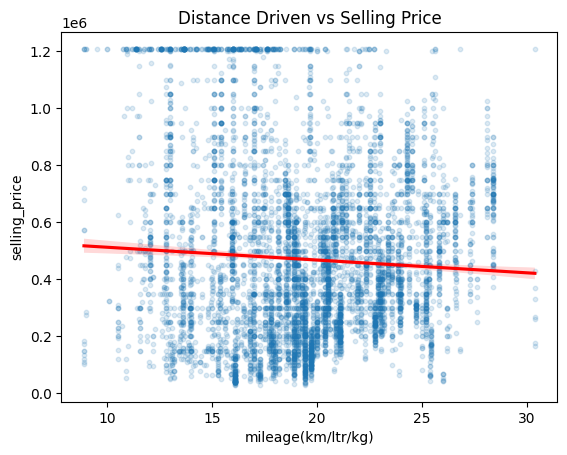

In [55]:
sns.regplot(x='mileage(km/ltr/kg)', y='selling_price', data=df,
            scatter_kws={'alpha': 0.15, 's': 10},
            line_kws={'color': 'red'})
plt.title('Distance Driven vs Selling Price')
plt.show()

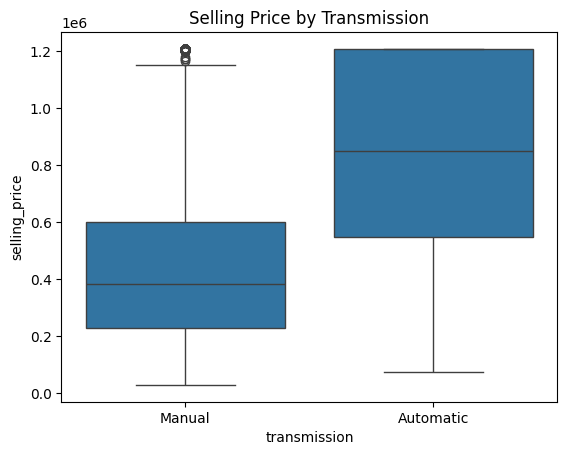

In [57]:
# Q5. Do automatic and manual cars differ in price?
sns.boxplot(x = 'transmission', y = 'selling_price', data = df)
plt.title('Selling Price by Transmission')
plt.show()


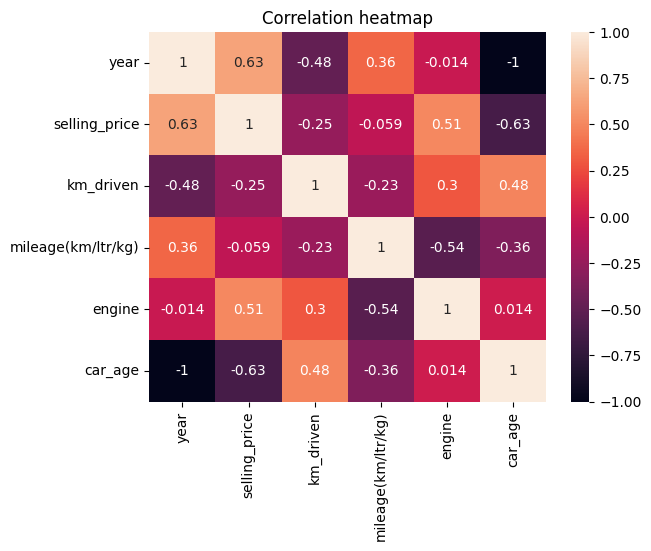

In [59]:
# Q6. Which features are strongly correlated?
sns.heatmap(df.select_dtypes(include = 'number').corr(), annot = True)
plt.title("Correlation heatmap")
plt.show()
# o/p : Car_age and Year

In [60]:
# Which brands have the highest average price?
df.groupby('brand')['selling_price'].mean().sort_values(ascending = False).head(10)
#o/p : Jaguar

,selling_price
brand,
Jaguar,1.208750e+06
Jeep,1.208750e+06
Lexus,1.208750e+06
Land,1.208750e+06
MG,1.208750e+06
Volvo,1.207778e+06
Isuzu,1.196562e+06
Audi,1.176061e+06
BMW,1.125106e+06


In [62]:
# Q8. Where are the important outliers or unusual records?
df.nlargest(10, 'selling_price')[['name', 'year', 'selling_price', 'km_driven']]

,name,year,selling_price,km_driven
41,Jeep Compass 1.4 Limited Plus BSIV,2019,1208750,5000
47,Toyota Fortuner 4x4 MT,2014,1208750,77000
49,Mercedes-Benz B Class B180,2014,1208750,27800
55,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1208750,127700
57,Audi A6 2.0 TDI Technology,2013,1208750,33900
58,Toyota Corolla Altis 1.8 VL CVT,2018,1208750,25000
59,Audi A6 2.0 TDI Design Edition,2013,1208750,50000
60,Mercedes-Benz New C-Class 220 CDI AT,2013,1208750,59000
75,Toyota Fortuner 4x4 MT,2015,1208750,78000
82,BMW X1 sDrive20i xLine,2016,1208750,30000
